# Problem 1

In [ ]:
import pandas as pd
import numpy as np

file_path = '/content/drive/MyDrive/SNA/undirected 8 node network.xlsx'

df = pd.read_excel(file_path, index_col=0)
print("Given data: \n", df)

# Replace '-' with 0
pd.set_option('future.no_silent_downcasting', True)
df = df.replace('-', 0).astype(int)

# Get adj matrix and nodes
adj_matrix = np.array(df.values)
node_labels = list(df.index)
print("\nAdjacency matrix:\n", adj_matrix)
print("\nNodes:\n", node_labels)

Given data: 
    A  B  C  D  E  F  G  H
A  -  1  1  0  0  0  0  0
B  1  -  1  1  1  0  0  0
C  1  1  -  0  1  1  1  0
D  0  1  0  -  0  0  0  1
E  0  1  1  0  -  0  0  1
F  0  0  1  0  0  -  1  0
G  0  0  1  0  0  1  -  1
H  0  0  0  1  1  0  1  -

Adjacency matrix:
 [[0 1 1 0 0 0 0 0]
 [1 0 1 1 1 0 0 0]
 [1 1 0 0 1 1 1 0]
 [0 1 0 0 0 0 0 1]
 [0 1 1 0 0 0 0 1]
 [0 0 1 0 0 0 1 0]
 [0 0 1 0 0 1 0 1]
 [0 0 0 1 1 0 1 0]]

Nodes:
 ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H']


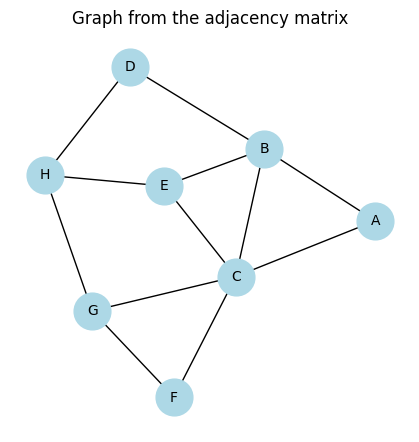

In [ ]:
# 2. Apply appropriate layout and properties for the nodes and edges
import networkx as nx
import matplotlib.pyplot as plt

labels_dict = {i: label for i, label in enumerate(node_labels)}

graph = nx.from_numpy_array(adj_matrix)
plt.figure(figsize=(4, 4))
pos = nx.spring_layout(graph)
nx.draw(graph, pos, with_labels=True, labels=labels_dict, node_color='lightblue', font_size=10, node_size=700)
plt.title('Graph from the adjacency matrix')
plt.show()

In [ ]:
# 3. Compute the following centrality measures of the graph.
#   a. Degree Centrality
#   b. Closeness Centrality
#   c. Betweenness Centrality for Node
#   d. Eigenvector Centrality
#   e. Katz Centrality

degree_centrality = nx.degree_centrality(graph)
print("Degree Centrality:\n", degree_centrality)

closeness_centrality = nx.closeness_centrality(graph)
print("\nCloseness Centrality:\n", closeness_centrality)

betweenness_centrality = nx.betweenness_centrality(graph)
print("\nBetweenness Centrality:\n", betweenness_centrality)

eigenvector_centrality = nx.eigenvector_centrality(graph, max_iter=100)
print("\nEigenvector Centrality:\n", eigenvector_centrality)

katz_centrality = nx.katz_centrality(graph, alpha=0.1)
print("\nKatz Centrality:\n", katz_centrality)

# 4. Write the interpretations based on the centrality measures.


Degree Centrality:
 {0: 0.2857142857142857, 1: 0.5714285714285714, 2: 0.7142857142857142, 3: 0.2857142857142857, 4: 0.42857142857142855, 5: 0.2857142857142857, 6: 0.42857142857142855, 7: 0.42857142857142855}

Closeness Centrality:
 {0: 0.5384615384615384, 1: 0.7, 2: 0.7777777777777778, 3: 0.5384615384615384, 4: 0.6363636363636364, 5: 0.5384615384615384, 6: 0.6363636363636364, 7: 0.5833333333333334}

Betweenness Centrality:
 {0: 0.0, 1: 0.19047619047619047, 2: 0.3333333333333333, 3: 0.03571428571428571, 4: 0.07142857142857142, 5: 0.0, 6: 0.10714285714285714, 7: 0.11904761904761904}

Eigenvector Centrality:
 {0: 0.2938295471153873, 1: 0.435445844258121, 2: 0.5217364755971936, 3: 0.22139279295554276, 4: 0.38155212769591407, 5: 0.2608324118497419, 6: 0.32795090689626855, 7: 0.28576218200515}

Katz Centrality:
 {0: 0.3233591254561516, 1: 0.384647900498665, 2: 0.4169456918909291, 3: 0.3162410570209338, 4: 0.3579356100852042, 5: 0.32004183970322997, 6: 0.35147500941361665, 7: 0.34576493478096

### Interpretations of Centrality Measures

Based on the computed centrality measures, we can interpret the roles of different nodes in the network:

**Node Labels Mapping:**
*   0: A
*   1: B
*   2: C
*   3: D
*   4: E
*   5: F
*   6: G
*   7: H

#### 1. Degree Centrality
*   **Definition:** Measures the number of direct connections a node has. Higher values indicate more direct influence or activity.
*   **Analysis:**
    *   **Node C (0.714):** Has the highest degree centrality, meaning it is directly connected to the most other nodes (5 connections). This suggests Node C is highly active and directly influential in the network.
    *   **Node B (0.571):** Also has a high degree, indicating it is well-connected.
    *   **Nodes A, D, F (0.286):** Have the lowest degree, indicating fewer direct connections and potentially less immediate influence.

#### 2. Closeness Centrality
*   **Definition:** Measures how close a node is to all other nodes in the network. Nodes with high closeness centrality can reach other nodes more quickly.
*   **Analysis:**
    *   **Node C (0.778):** Has the highest closeness centrality, implying it can reach all other nodes in the network in a relatively short number of steps. This makes it efficient for information dissemination.
    *   **Node B (0.700) and E (0.636), G (0.636):** Also show good closeness, suggesting they are relatively central in terms of reachability.
    *   **Nodes A, D, F (0.538):** Have lower closeness, indicating they are further away from other nodes on average.

#### 3. Betweenness Centrality
*   **Definition:** Measures the extent to which a node lies on the shortest paths between other nodes. Nodes with high betweenness centrality act as 'bridges' or 'gatekeepers' for information flow.
*   **Analysis:**
    *   **Node C (0.333):** Has the highest betweenness centrality, indicating it frequently lies on the shortest paths between many pairs of nodes. This makes Node C crucial for controlling or facilitating information flow in the network.
    *   **Node B (0.190):** Also shows significant betweenness, playing an important bridging role.
    *   **Nodes A, F (0.0):** Have zero betweenness, meaning they do not lie on any shortest paths between other nodes, suggesting they are not critical for connecting disparate parts of the network.

#### 4. Eigenvector Centrality
*   **Definition:** Measures a node's influence based on its connections to other highly connected nodes. A node with high eigenvector centrality is connected to many other important nodes.
*   **Analysis:**
    *   **Node C (0.522):** Possesses the highest eigenvector centrality, suggesting it is connected to other influential nodes, amplifying its own importance.
    *   **Node B (0.435) and E (0.382):** Also have high eigenvector scores, implying their connections are to other significant nodes.
    *   **Node D (0.221):** Has the lowest eigenvector centrality, indicating its connections are not primarily to other highly influential nodes.

#### 5. Katz Centrality
*   **Definition:** Measures a node's influence by considering both direct and indirect connections, with more weight given to closer connections. It is often used when paths are important, even if not shortest.
*   **Analysis:**
    *   **Node C (0.417):** Ranks highest in Katz centrality, reinforcing its overall importance and influence through both direct and indirect ties throughout the network.
    *   **Node B (0.385) and E (0.358), G (0.351):** Are also highly central by this measure, showing strong overall reach and influence.
    *   **Node D (0.316):** Has the lowest Katz centrality, suggesting a more peripheral role in terms of overall network influence.

### Overall Interpretation:

**Node C** consistently ranks as the most central node across almost all measures (Degree, Closeness, Betweenness, Eigenvector, Katz). This indicates that Node C is:
*   **Highly Active:** Has many direct connections.
*   **Efficient:** Can quickly reach other nodes.
*   **Influential:** Connects to other important nodes and acts as a crucial bridge for information flow.

Nodes like **A, D, and F** generally exhibit lower centrality across the board, implying they are more peripheral and less critical for the overall structure and flow of information in this network.

# Problem 2 - skill graph

In [23]:
# 3. Load the dataset using the appropriate library in Python 3.X and generate the graph.

import networkx as nx
import matplotlib.pyplot as plt

file_path = '/content/drive/MyDrive/SNA/skillgraph.gexf'
graph = nx.read_gexf(file_path, node_type=None, relabel=False)
print(graph)

Graph with 130 nodes and 1210 edges


In [20]:
# 4. Find the following information based on each dataset:
#   a. Number of nodes and edges
#   b. Eccentricity of the graph

print("Number of nodes:", graph.number_of_nodes())
print("Number of edges:", graph.number_of_edges())

eccentricity = nx.eccentricity(graph)
print("\nEccentricity of the graph:\n", eccentricity)

Number of nodes: 130
Number of edges: 1210

Eccentricity of the graph:
 {'Test management': 3, 'Automation': 3, 'SUSE Linux': 4, 'Test scenarios': 3, 'Performance tuning': 3, 'Apache Tomcat': 4, 'Database': 3, 'Ubuntu': 4, 'Planning': 3, 'Microsoft Project': 3, 'Oracle WebLogic': 4, 'Red Hat Enterprise Linux': 4, 'Web QA': 3, 'Senior management': 3, 'Database design': 3, 'QA': 2, 'PMBOK': 4, 'Unix': 3, 'Spring': 3, 'HTML5': 3, 'Test execution': 3, 'Linux': 3, 'Shell scripting': 3, 'IT project management': 3, 'HTML': 3, 'Solaris administration': 4, 'Test cases': 3, 'IBM AIX': 4, 'Web services': 3, 'PMP': 3, 'Tcl': 4, 'Apache Hadoop': 3, 'Selenium': 3, 'Scripting language': 4, 'Big data': 3, 'SOAP': 3, 'CSS': 3, 'Functional testing': 3, 'Web development': 3, 'Project planning': 3, 'Scripting': 3, 'SDET': 3, 'Apache HBase': 4, 'Ajax': 3, 'OOP': 3, 'Project management': 3, 'Test scripts': 3, 'Project implementation': 4, 'Estimating': 3, 'Leadership': 3, 'Enterprise software': 3, 'JavaScrip

In [21]:
# c. The node that has the highest degree centrality, closeness centrality, betweenness centrality, Eigen-Vector and Katz centrality

degree_centrality = nx.degree_centrality(graph)
print("Degree Centrality:\n", degree_centrality)

closeness_centrality = nx.closeness_centrality(graph)
print("\nCloseness Centrality:\n", closeness_centrality)

betweenness_centrality = nx.betweenness_centrality(graph)
print("\nBetweenness Centrality:\n", betweenness_centrality)

eigenvector_centrality = nx.eigenvector_centrality(graph, max_iter=1000)
print("\nEigenvector Centrality:\n", eigenvector_centrality)

katz_centrality = nx.katz_centrality(graph, alpha=0.01, max_iter=1000)
print("\nKatz Centrality:\n", katz_centrality)

Degree Centrality:
 {'Test management': 0.09302325581395349, 'Automation': 0.21705426356589147, 'SUSE Linux': 0.07751937984496124, 'Test scenarios': 0.10077519379844961, 'Performance tuning': 0.08527131782945736, 'Apache Tomcat': 0.12403100775193798, 'Database': 0.2248062015503876, 'Ubuntu': 0.05426356589147287, 'Planning': 0.1937984496124031, 'Microsoft Project': 0.15503875968992248, 'Oracle WebLogic': 0.10852713178294573, 'Red Hat Enterprise Linux': 0.06201550387596899, 'Web QA': 0.11627906976744186, 'Senior management': 0.14728682170542634, 'Database design': 0.10852713178294573, 'QA': 0.5271317829457365, 'PMBOK': 0.11627906976744186, 'Unix': 0.2558139534883721, 'Spring': 0.17829457364341084, 'HTML5': 0.12403100775193798, 'Test execution': 0.10852713178294573, 'Linux': 0.3178294573643411, 'Shell scripting': 0.14728682170542634, 'IT project management': 0.17054263565891473, 'HTML': 0.16279069767441862, 'Solaris administration': 0.05426356589147287, 'Test cases': 0.20155038759689922, 

In [22]:
print('Node with highest')
print(' - Degree Centrality: ', max(degree_centrality, key=degree_centrality.get))
print(' - Closeness Centrality: ', max(closeness_centrality, key=degree_centrality.get))
print(' - Betweenness Centrality: ', max(betweenness_centrality, key=degree_centrality.get))
print(' - Eigenvector Centrality: ', max(eigenvector_centrality, key=degree_centrality.get))
print(' - Katz Centrality: ', max(katz_centrality, key=degree_centrality.get))

Node with highest
 - Degree Centrality:  QA
 - Closeness Centrality:  QA
 - Betweenness Centrality:  QA
 - Eigenvector Centrality:  QA
 - Katz Centrality:  QA


d. What is your interpretation on each graph based on the results of the node centrality?

### Interpretations of Centrality Measures for the Skill Graph

Based on the computed centrality measures for the 'skill graph', we can interpret the roles of different skills in the network.

From the analysis, the skill **'QA'** consistently ranks highest across all centrality measures:

*   **Degree Centrality:** QA
*   **Closeness Centrality:** QA
*   **Betweenness Centrality:** QA
*   **Eigenvector Centrality:** QA
*   **Katz Centrality:** QA

Let's break down the interpretation for each measure:

#### 1. Degree Centrality
*   **Definition:** Measures the number of direct connections a node has. Higher values indicate more direct influence or activity.
*   **Analysis:**
    *   **QA (0.527):** Has the highest degree centrality, meaning it is directly connected to a significant number of other skills. This suggests 'QA' is a highly active and fundamental skill, directly related to many other areas.
    *   **Java (0.496) and Leadership (0.450):** Also have very high degrees, indicating their strong direct connectivity within the skill set.
    *   **Enterprise software (0.031), Flask (0.031), Nginx (0.031), GUI (0.039), Scalability (0.039), Natural language processing (0.039):** Have some of the lowest degrees, implying fewer direct connections to other skills.

#### 2. Closeness Centrality
*   **Definition:** Measures how close a node is to all other nodes in the network. Nodes with high closeness centrality can reach other nodes more quickly.
*   **Analysis:**
    *   **QA (0.679):** Possesses the highest closeness centrality, indicating that it can reach all other skills in the network in a minimal number of steps. This makes 'QA' highly efficient for information dissemination and integration across different skills.
    *   **Java (0.658), Leadership (0.632), SQL (0.611):** Also exhibit very high closeness, suggesting they are central in terms of reachability within the skill network.
    *   **Mainframe QA (0.335), Contingency plan (0.341), Natural language processing (0.377):** Have lower closeness, suggesting they are relatively further from other skills on average.

#### 3. Betweenness Centrality
*   **Definition:** Measures the extent to which a node lies on the shortest paths between other nodes. Nodes with high betweenness centrality act as 'bridges' or 'gatekeepers' for information flow.
*   **Analysis:**
    *   **QA (0.181):** Has the highest betweenness centrality, signifying that it frequently lies on the shortest paths between many pairs of skills. This makes 'QA' a critical skill for connecting disparate skill sets and facilitating collaboration or knowledge transfer.
    *   **Java (0.136) and Leadership (0.133):** Also show substantial betweenness, implying their importance in bridging different skill areas.
    *   **Skills with 0.0 betweenness (e.g., 'Project delivery', 'Flask', 'HP-UX'):** These skills do not lie on any shortest paths between other nodes, suggesting they are not crucial for connecting different parts of the network in this context.

#### 4. Eigenvector Centrality
*   **Definition:** Measures a node's influence based on its connections to other highly connected nodes. A node with high eigenvector centrality is connected to many other important nodes.
*   **Analysis:**
    *   **QA (0.245):** Has the highest eigenvector centrality, suggesting it is highly connected to other influential and central skills, thus amplifying its own importance and influence within the network.
    *   **Java (0.239), Leadership (0.216), SQL (0.213):** Also have high eigenvector scores, indicating their connections are primarily to other significant skills.
    *   **Natural language processing (0.008), Flask (0.009), Nginx (0.009):** Have some of the lowest eigenvector centralities, implying their connections are not predominantly to other highly influential skills.

#### 5. Katz Centrality
*   **Definition:** Measures a node's influence by considering both direct and indirect connections, with more weight given to closer connections. It is often used when paths are important, even if not shortest.
*   **Analysis:**
    *   **QA (0.132):** Ranks highest in Katz centrality, reinforcing its overall importance and influence through both direct and indirect ties throughout the network. This highlights 'QA's' comprehensive reach and impact.
    *   **Java (0.128), Leadership (0.123), SQL (0.115):** Are also highly central by this measure, demonstrating strong overall reach and influence across the skill graph.
    *   **Flask (0.073), Nginx (0.073), Scalability (0.075), GWT (0.075):** Have the lowest Katz centrality, suggesting a more peripheral role in terms of overall network influence.

### Overall Interpretation for the Skill Graph:

The skill **'QA'** stands out as the most critical and central node in this skill graph. Its consistently high scores across all centrality measures indicate that 'QA' is:

*   **Highly Active and Connected:** Directly linked to a large number of other skills.
*   **Efficient and Reachable:** Can quickly access and be accessed by other skills.
*   **Crucially Bridging:** Acts as a vital intermediary for information and collaboration flow between diverse skill sets.
*   **Highly Influential:** Connected to other important skills, boosting its own significance.

Other skills like **Java, Leadership, and SQL** also show significant centrality, playing important roles in connecting, influencing, and being accessible within the network. In contrast, skills such as **Enterprise software, Flask, Nginx, GUI, Scalability, and Natural language processing** appear to be more specialized or niche, with fewer connections and less overall influence on the broader skill network.

In [24]:
# 5. Apply various layouts and properties available in the visualization.

# get the labels
labels_dict = {node: node for node in graph.nodes()}

# spring layout
plt.figure(figsize=(16, 16))
pos_1 = nx.spring_layout(graph)
nx.draw(graph, pos_1, with_labels=True, labels=labels_dict, node_color='lightpink', font_size=6, node_size=600)
plt.title('Skill graph - spring layout')

# circular layout
plt.figure(figsize=(16, 16))
pos_2 = nx.circular_layout(graph)
nx.draw(graph, pos_2, with_labels=True, labels=labels_dict, node_color='lightblue', font_size=6, node_size=600)
plt.title('Skill graph - circular layout')

# spectral layout
plt.figure(figsize=(20, 20))
pos_3 = nx.spectral_layout(graph)
nx.draw(graph, pos_3, with_labels=True, labels=labels_dict, node_color='yellow', font_size=6, node_size=700)
plt.title('Skill graph - spectral layout')

# shell layout
plt.figure(figsize=(20, 20))
pos_4 = nx.shell_layout(graph)
nx.draw(graph, pos_4, with_labels=True, labels=labels_dict, node_color='lightgreen', font_size=6, font_color='blue', node_size=800)
plt.title('Skill graph - shell layout')

# random layout
plt.figure(figsize=(20, 20))
pos_5 = nx.random_layout(graph)
nx.draw(graph, pos_5, with_labels=True, labels=labels_dict, node_color='orange', font_size=6,  node_size=800)
plt.title('Skill graph - random layout')

plt.show()

Output hidden; open in https://colab.research.google.com to view.

# Problem 3 - Facebook network

In [25]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

# 1. Download the Facebook dataset. (Dataset links provided)
facebook = pd.read_csv(
    "/content/drive/MyDrive/SNA/facebook_combined.txt.gz",
    compression="gzip",
    sep=" ",
    names=["start_node", "end_node"],
)
facebook.head()

,start_node,end_node
0,0,1
1,0,2
2,0,3
3,0,4
4,0,5


In [26]:
# 2. Generate the social network to analyse the Facebook data.

graph = nx.from_pandas_edgelist(facebook, "start_node", "end_node")
print(graph)

Graph with 4039 nodes and 88234 edges


In [28]:
# 3. Apply the centrality measures and clustering coefficient measure to study the nature of the network.

degree_centrality = nx.degree_centrality(graph)
print("\nDegree Centrality:\n", degree_centrality)


Degree Centrality:
 {0: 0.08593363051015354, 1: 0.004210004952947003, 2: 0.0024764735017335313, 3: 0.004210004952947003, 4: 0.0024764735017335313, 5: 0.0032194155522535907, 6: 0.0014858841010401188, 7: 0.004952947003467063, 8: 0.001981178801386825, 9: 0.014115898959881128, 10: 0.0024764735017335313, 11: 0.00024764735017335313, 12: 0.00024764735017335313, 13: 0.007677067855373947, 14: 0.003714710252600297, 15: 0.00024764735017335313, 16: 0.002228826151560178, 17: 0.0032194155522535907, 18: 0.00024764735017335313, 19: 0.00396235760277365, 20: 0.003714710252600297, 21: 0.016097077761267953, 22: 0.0027241208519068845, 23: 0.004210004952947003, 24: 0.00396235760277365, 25: 0.017087667161961365, 26: 0.016840019811788013, 27: 0.0012382367508667657, 28: 0.0032194155522535907, 29: 0.0032194155522535907, 30: 0.004210004952947003, 31: 0.005695889053987122, 32: 0.0014858841010401188, 33: 0.0004952947003467063, 34: 0.0012382367508667657, 35: 0.0004952947003467063, 36: 0.0027241208519068845, 37: 0.

In [30]:
closeness_centrality = nx.closeness_centrality(graph)
print("\nCloseness Centrality:\n", closeness_centrality)


Closeness Centrality:
 {0: 0.35334266713335666, 1: 0.2613761408505405, 2: 0.26125776397515527, 3: 0.2613761408505405, 4: 0.26125776397515527, 5: 0.2613084837895554, 6: 0.26119016817593793, 7: 0.2747686445291236, 8: 0.2612239617026782, 9: 0.2620546433902265, 10: 0.26125776397515527, 11: 0.26110572259941806, 12: 0.26110572259941806, 13: 0.26161321671525756, 14: 0.2613423079412336, 15: 0.26110572259941806, 16: 0.2612408617454875, 17: 0.2613084837895554, 18: 0.26110572259941806, 19: 0.2613592233009709, 20: 0.2613423079412336, 21: 0.2756125861715924, 22: 0.2612746683921061, 23: 0.2613761408505405, 24: 0.2613592233009709, 25: 0.26225888160031174, 26: 0.26224184959085595, 27: 0.2611732746911584, 28: 0.2613084837895554, 29: 0.2613084837895554, 30: 0.2613761408505405, 31: 0.2614776921582594, 32: 0.26119016817593793, 33: 0.26112260734609416, 34: 0.3033125516412529, 35: 0.26112260734609416, 36: 0.2612746683921061, 37: 0.26110572259941806, 38: 0.2612408617454875, 39: 0.2613423079412336, 40: 0.261

In [31]:
betweenness_centrality = nx.betweenness_centrality(graph)
print("\nBetweenness Centrality:\n", betweenness_centrality)


Betweenness Centrality:
 {0: 0.14630592147442917, 1: 2.7832744209034606e-06, 2: 7.595021178512074e-08, 3: 1.6850656559280464e-06, 4: 1.8403320547933104e-07, 5: 2.205964164092193e-06, 6: 2.4537760730577472e-08, 7: 0.0001702984836730339, 8: 2.7604980821899654e-07, 9: 1.6454236303026905e-05, 10: 4.986739552037655e-08, 11: 0.0, 12: 0.0, 13: 1.7622717578436846e-06, 14: 5.582871686568508e-07, 15: 0.0, 16: 1.9979459275532697e-07, 17: 4.1066669000480344e-07, 18: 0.0, 19: 5.062957964075819e-06, 20: 6.793693332142838e-07, 21: 0.0009380243844653233, 22: 6.703002200833232e-07, 23: 6.860348937590618e-06, 24: 1.3673472422981514e-07, 25: 5.38808313945586e-05, 26: 1.935436798204632e-05, 27: 3.067220091322184e-08, 28: 3.812160659244892e-07, 29: 1.3954817951917517e-06, 30: 1.3694627409316544e-06, 31: 4.932641252790837e-06, 32: 0.0, 33: 0.0, 34: 0.0036020881281963652, 35: 0.0, 36: 2.726417858953052e-08, 37: 0.0, 38: 7.344481172858835e-07, 39: 9.548632622274015e-07, 40: 1.3796059569123122e-05, 41: 4.6732

In [29]:
eigenvector_centrality = nx.eigenvector_centrality(graph, max_iter=1000)
print("\nEigenvector Centrality:\n", eigenvector_centrality)


Eigenvector Centrality:
 {0: 3.391796172270201e-05, 1: 6.045346134948107e-07, 2: 2.2334609371911966e-07, 3: 6.635648083921052e-07, 4: 2.2364157028893605e-07, 5: 1.1833221118435216e-06, 6: 2.1709041695161263e-07, 7: 2.568510124822489e-05, 8: 2.1973746334830285e-07, 9: 2.214116624486093e-06, 10: 7.708567044092624e-07, 11: 2.1031233303459666e-07, 12: 2.1031233303459666e-07, 13: 1.103790547598573e-06, 14: 2.3055679294325335e-07, 15: 2.1031233303459666e-07, 16: 2.616513592117462e-07, 17: 2.2774170298520142e-07, 18: 2.1031233303459666e-07, 19: 2.3149092118602842e-07, 20: 2.3038875741121886e-07, 21: 2.5965755464539663e-05, 22: 1.0365420550578182e-06, 23: 2.327855955467465e-07, 24: 2.4875636881516775e-07, 25: 2.0920477409908786e-06, 26: 2.333621078244131e-06, 27: 3.8500493368810947e-07, 28: 2.276328150659143e-07, 29: 2.9276633115487333e-07, 30: 9.62912044010581e-07, 31: 1.4530295555049823e-06, 32: 2.172656002138456e-07, 33: 2.1162712130634827e-07, 34: 4.074184547679874e-06, 35: 2.117140285304

In [14]:
clustering = nx.clustering(graph)
print("\nClustering coefficient:\n", clustering)


Clustering coefficient:
 {0: 0.04196165314587463, 1: 0.41911764705882354, 2: 0.8888888888888888, 3: 0.6323529411764706, 4: 0.8666666666666667, 5: 0.3333333333333333, 6: 0.9333333333333333, 7: 0.43157894736842106, 8: 0.6785714285714286, 9: 0.39724310776942356, 10: 0.8222222222222222, 11: 0, 12: 0, 13: 0.6516129032258065, 14: 0.7428571428571429, 15: 0, 16: 0.6666666666666666, 17: 0.7307692307692307, 18: 0, 19: 0.2833333333333333, 20: 0.6857142857142857, 21: 0.3490384615384615, 22: 0.4727272727272727, 23: 0.16911764705882354, 24: 0.9, 25: 0.2885763000852515, 26: 0.4113257243195786, 27: 0.9, 28: 0.7692307692307693, 29: 0.46153846153846156, 30: 0.5, 31: 0.43478260869565216, 32: 1.0, 33: 1.0, 34: 0.6, 35: 1.0, 36: 0.9636363636363636, 37: 0, 38: 0.3611111111111111, 39: 0.49523809523809526, 40: 0.4048625792811839, 41: 0.4673913043478261, 42: 1.0, 43: 0, 44: 1.0, 45: 0.7272727272727273, 46: 1.0, 47: 1.0, 48: 0.329004329004329, 49: 0.5, 50: 0.5636363636363636, 51: 0.8571428571428571, 52: 1.0, 5

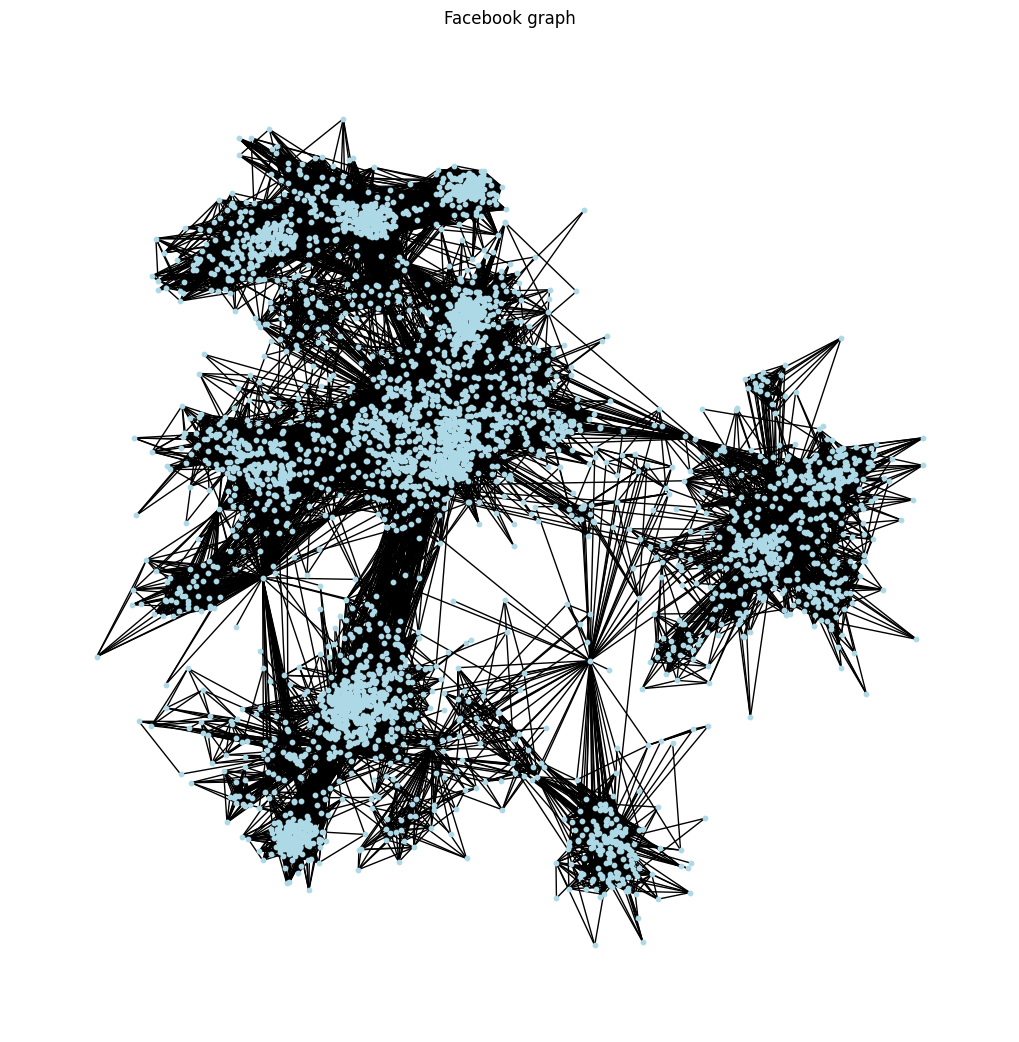

In [16]:
# 4. Write your interpretations based on the results of the measures and visualization.

# Facebook graph visualization

plt.figure(figsize=(10, 10))
pos = nx.spring_layout(graph)
nx.draw(graph, pos, node_size=10, node_color='lightBlue')
plt.title('Facebook graph')
plt.show()

In [32]:
# Interpretation

print('Node with highest')
print(' - Degree Centrality: ', max(degree_centrality, key=degree_centrality.get))
print(' - Closeness Centrality: ', max(closeness_centrality, key=degree_centrality.get))
print(' - Betweenness Centrality: ', max(betweenness_centrality, key=degree_centrality.get))
print(' - Eigenvector Centrality: ', max(eigenvector_centrality, key=degree_centrality.get))

print('Clustering Coefficient: ')
print(' - Node with highest clustering coefficient: ', max(clustering, key=clustering.get))
print(' - Node with lowest clustering coefficient: ', min(clustering, key=clustering.get))

Node with highest
 - Degree Centrality:  107
 - Closeness Centrality:  107
 - Betweenness Centrality:  107
 - Eigenvector Centrality:  107
Clustering Coefficient: 
 - Node with highest clustering coefficient:  32
 - Node with lowest clustering coefficient:  11
